# EDA – Unit commitment in the Tokke–Vinje hydropower system

In [1]:
# import packages
import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml


## 1. Loading and cleaning the data

In [2]:
# load data
water_value = pd.read_csv("data/kernel/Synthetic_water_value_2015_2024.csv",
    parse_dates=["date"],
    index_col="date"
)

volume = pd.read_csv("data/kernel/Historical_volume_2015_2024.csv",
    parse_dates=["date"],
    index_col="date"
)

day_ahead_price = pd.read_csv("data/kernel/Historical_day_ahead_price_2015_2025.csv",
    parse_dates=["date"],
    index_col="date"
)

# rename price column and resample to hourly for the 15 minute interval period
day_ahead_price = day_ahead_price.rename(columns={"Day-ahead price (EUR/MWh)": "price"})
day_ahead_price = day_ahead_price.resample("h").mean()

inflow = pd.read_csv("data/kernel/Historical_inflow_1958_2025.csv",
    parse_dates=["date"],
    index_col="date"
)

# Unit commitment decisions have no date column, so we use starttime instead
unit_commitment_decisions = pd.read_csv("data/kernel/Unit_commitment_decisions.csv",
    parse_dates=["starttime"],
    index_col="starttime"
)

# drop the timezone for consistency
water_value.index = water_value.index.tz_convert(None)
volume.index = volume.index.tz_convert(None)
day_ahead_price.index = day_ahead_price.index.tz_convert(None)
inflow.index = inflow.index.tz_convert(None)

# reservoir fill level as a share of max volume (max_vol from the topology file)
with open("data/extended/Tokke_Vinje_topology.yaml") as f:
    topology = yaml.safe_load(f)

max_vol = pd.Series({name: r["max_vol"] for name, r in topology["model"]["reservoir"].items()})
fill = volume / max_vol

# overview of all loaded datasets
datasets = {
    "water_value": water_value,
    "volume": volume,
    "day_ahead_price":day_ahead_price,
    "inflow": inflow,
    "unit_commitment_decisions": unit_commitment_decisions
}

summary = pd.DataFrame({
    name: {
        "rows": df.shape[0],
        "columns": df.shape[1],
        "start": df.index.min(),
        "end": df.index.max(),
        "missing values": df.isna().sum().sum(),
        "duplicate timestamps": df.index.duplicated().sum()
    }
    for name, df in datasets.items()
}).T

summary

,rows,columns,start,end,missing values,duplicate timestamps
water_value,3654,17,2015-01-01 00:00:00,2025-01-01 00:00:00,0,0
volume,3654,17,2015-01-01 00:00:00,2025-01-01 00:00:00,0,0
day_ahead_price,96432,1,2015-01-01 00:00:00,2025-12-31 23:00:00,0,0
inflow,594224,18,1958-01-01 00:00:00,2025-10-15 07:00:00,0,0
unit_commitment_decisions,2922,2354,2015-01-01 00:00:00,2022-12-31 00:00:00,0,0


None of the datasets have missing values or duplicate timestamps. Cleaning steps:
- **Time zones:** all input files have UTC timestamps (`+00:00`), while `starttime` in the label file has none. The time zone was removed from all inputs so the files can be compared directly; everything is in UTC.
- **Price resolution:** the day-ahead price switches from hourly to 15-minute steps from 2025-09-30. It was resampled to hourly averages, since all cases are hourly.
- **Reservoir fill level:** volumes were converted to fill level (volume / max_vol from `Tokke_Vinje_topology.yaml`). Some values exceed 1 (max 1.18 for Bandak), see section 3.

Time coverage: price, water value and volume start in 2015, inflow goes back to 1958. The labels cover 2015–2022 (2,922 cases); the test period is 2023–2024 (725 cases in `prediction_mapping.csv`).

In [3]:
# Check that the input data covers every case: training (labels) and test (prediction_mapping)
test_cases = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])

for period, starts in {
    "train": unit_commitment_decisions.index,
    "test": pd.DatetimeIndex(test_cases["starttime"]),
}.items():
    ends = starts + pd.Timedelta(days=7)
    last_hour = starts.max() + pd.Timedelta(hours=167)
    print(f"--- {period}: {len(starts)} cases, {starts.min().date()} → {starts.max().date()}")
    print("Water value start/end OK:", starts.isin(water_value.index).all(), ends.isin(water_value.index).all())
    print("Volume start OK:", starts.isin(volume.index).all())
    print("Price covers all hours:", day_ahead_price.index.max() >= last_hour)
    print("Inflow covers all hours:", inflow.index.max() >= last_hour)

--- train: 2922 cases, 2015-01-01 → 2022-12-31
Water value start/end OK: True True
Volume start OK: True
Price covers all hours: True
Inflow covers all hours: True
--- test: 725 cases, 2023-01-01 → 2024-12-25
Water value start/end OK: True True
Volume start OK: True
Price covers all hours: True
Inflow covers all hours: True


All input data covers every training and test case, including the water value 7 days after the start (the end of each case). The last test case starts 2024-12-25 and uses the water value from 2025-01-01, the final row of the file, so the data was clearly prepared with the test period in mind.

## 2. Exploring the labels (unit commitment)

In [4]:
#Find the units in column names
label_cols = [c for c in unit_commitment_decisions.columns if c.startswith("result_committed")]

units = []
for c in label_cols:
    unit = c.replace("result_committed_", "").rsplit("_t", 1)[0] # making the names: "Hogga_G1_t5" -> "Hogga_G1"
    if unit not in units:
        units.append(unit)

print(len(units), units)

# The columns come in order: all 168 hours for unit 1, then all 168 for unit 2, up to 14
Y = unit_commitment_decisions[label_cols].to_numpy().reshape(len(unit_commitment_decisions), len(units), 168)
Y.shape


14 ['Hogga_G1', 'Tokke_G1', 'Tokke_G2', 'Tokke_G3', 'Tokke_G4', 'Lio_G1', 'Byrte_G1', 'Vinje_G1', 'Vinje_G2', 'Vinje_G3', 'Haukeli_G1', 'Songa_G1', 'Kjela_G1', 'Vesle Kjela_G1']


(2922, 14, 168)

In [5]:
# reshape check: unit 0 = Hogga_G1, unit 13 = Vesle Kjela_G1
assert (Y[0, 0, :] == unit_commitment_decisions.filter(like="Hogga_G1_t").iloc[0].to_numpy()).all()
assert (Y[5, 13, :] == unit_commitment_decisions.filter(like="Vesle Kjela_G1_t").iloc[5].to_numpy()).all()
print("Reshape OK, labels only 0/1:", set(pd.unique(Y.ravel())))

Reshape OK, labels only 0/1: {np.int64(0), np.int64(1)}


In [6]:
#The overall on-rate
print(f"Overall on rate: {Y.mean():.1%}")

Overall on rate: 51.6%


The fact that the overall on-rate is 51.6% tells us that the classes are balanced. 

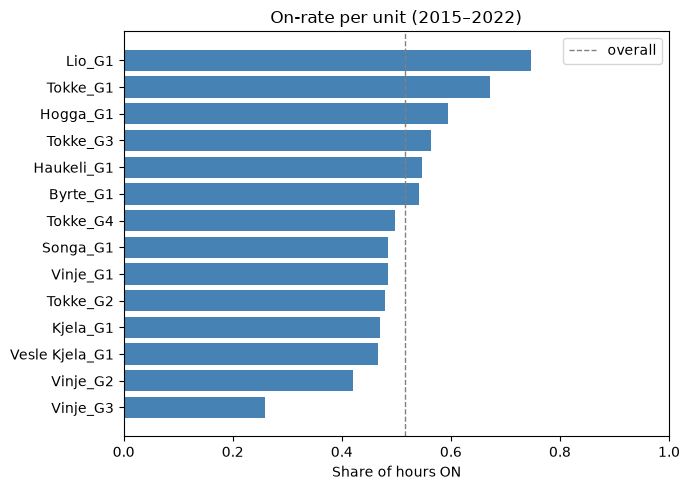

In [7]:
#Plot on-rate per unit
unit_rate = pd.Series(Y.mean(axis=(0, 2)), index=units).sort_values()

fig, ax2 = plt.subplots(figsize=(7, 5))
ax2.barh(unit_rate.index, unit_rate.values, color="steelblue")
ax2.axvline(Y.mean(), color="grey", linestyle="--", linewidth=1, label="overall")
ax2.set_xlabel("Share of hours ON")
ax2.set_xlim(0, 1)
ax2.set_title("On-rate per unit (2015–2022)")
ax2.legend()
plt.tight_layout()

The units differ a lot: Vinje_G3 is rarely on (~25% of hours), while Lio_G1 is on most of the time (~75%).

In [8]:
# Function for plotting on-rate per unit
def plot_on_rate_heatmap(rates, title, ax):
    im = ax.imshow(rates.T, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(rates.index)), rates.index)
    ax.set_yticks(range(len(rates.columns)), rates.columns)
    for i in range(len(rates.columns)):
        for j in range(len(rates.index)):
            v = rates.iloc[j, i]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.6 else "black", fontsize=7)
    ax.set_title(title)
    return im

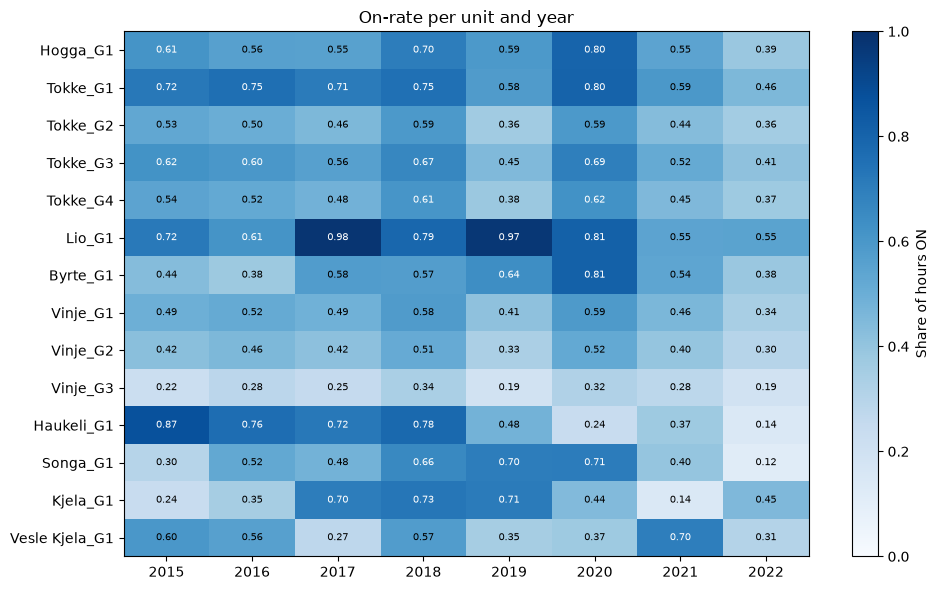

In [9]:
# Plot on-rate per unit per year
years = unit_commitment_decisions.index.year
rate_by_year = pd.DataFrame(Y.mean(axis=2), columns=units).groupby(years).mean()

fig, ax = plt.subplots(figsize=(10, 6))
im = plot_on_rate_heatmap(rate_by_year, "On-rate per unit and year", ax)
fig.colorbar(im, ax=ax, label="Share of hours ON")
plt.tight_layout()

The on-rate changes a lot between years. Haukeli_G1 fell from 0.87 in 2015 to 0.14 in 2022, and units like Lio_G1 and Kjela_G1 jump up and down. Two consequences for the model:
- **Validation must be time-based** (train on earlier years, validate on later). A random split would also leak information, since consecutive cases overlap by 6 of 7 days.
- **Which unit it is says little on its own.** The model has to learn from the conditions each week, such as price, water value and reservoir level, rather than from how often a unit is usually on.

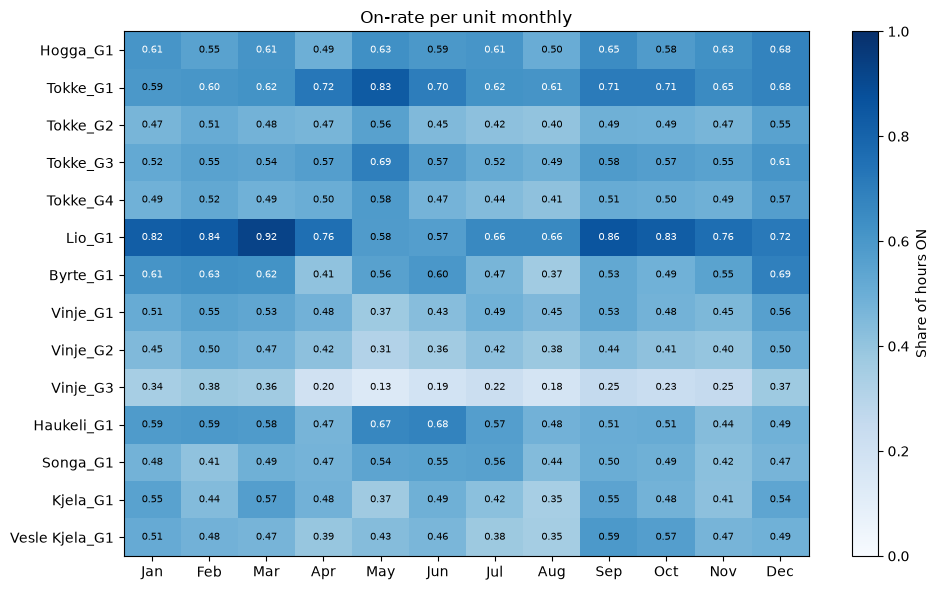

In [10]:
# Plot on-rate per unit seasonally
rate_by_month = pd.DataFrame(Y.mean(axis=2), columns=units).groupby(unit_commitment_decisions.index.month).mean()
rate_by_month.index = [calendar.month_abbr[m] for m in rate_by_month.index]
fig_month, ax_month = plt.subplots(figsize=(10, 6))
im_month = plot_on_rate_heatmap(rate_by_month, "On-rate per unit monthly", ax_month)
fig_month.colorbar(im_month, ax=ax_month, label="Share of hours ON")
plt.tight_layout()

There is no common seasonal pattern for all units, but some clear unit-specific ones:
- **May (snowmelt):** Tokke goes up (G1: 0.83) while Vinje goes down (G3: 0.13). Tokke draws from Vinjevatn, which is very small (max 9.4 Mm³) and fills quickly with snowmelt, so Tokke has to run to avoid spilling water. Vinje releases its water *into* Vinjevatn, so running it then would only add to the problem.
- **Lio_G1** drops from ~0.9 in March to ~0.57 in May–June.
- **August** has the lowest average on-rate across units, possibly because of low summer prices.

The season therefore matters through *inflow and reservoir state*, which suggests using those as features rather than just the month.

## 3. Input data over time

In [11]:
# Periods used in all time plots
periods = {
    "train (2015–2020)": ("2015-01-01", "2020-12-31", "tab:blue"),
    "validation (2021–2022)": ("2021-01-01", "2022-12-31", "tab:orange"),
    "test (2023–2024)": ("2023-01-01", "2024-12-31", "tab:green"),
}

def shade_periods(ax):
    for label, (start, end, color) in periods.items():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.08, label=label)

train (2015–2020): average std within a day = 2.1 EUR/MWh
validation (2021–2022): average std within a day = 21.2 EUR/MWh
test (2023–2024): average std within a day = 14.3 EUR/MWh


,mean,std,min,max,negative hours
train (2015–2020),27.6,13.7,-1.7,114.7,5.0
validation (2021–2022),143.2,116.9,-2.0,844.0,5.0
test (2023–2024),64.8,38.2,-61.8,898.2,380.0


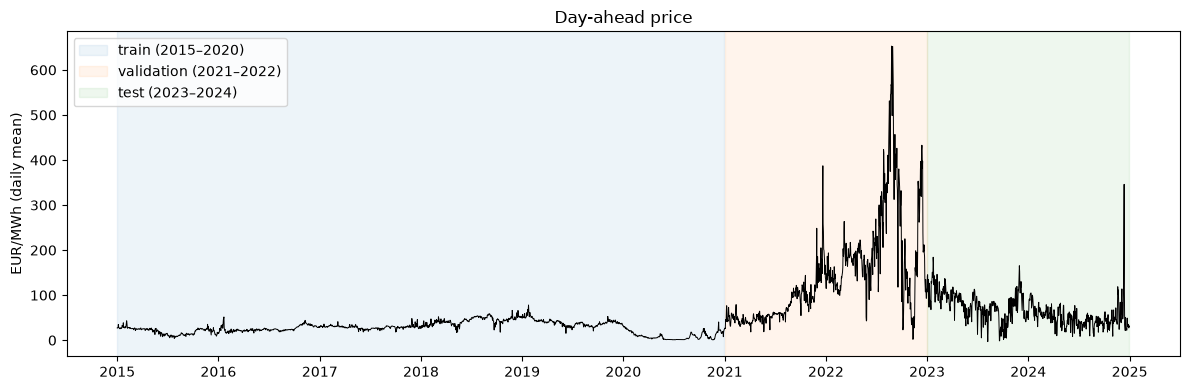

In [12]:
price_daily = day_ahead_price["price"].loc[:"2024"].resample("D").mean()

fig, ax = plt.subplots(figsize=(12, 4))
shade_periods(ax)
ax.plot(price_daily.index, price_daily, color="black", linewidth=0.7)
ax.set_ylabel("EUR/MWh (daily mean)")
ax.set_title("Day-ahead price")
ax.legend(loc="upper left")
plt.tight_layout()

price_2024 = day_ahead_price["price"].loc[:"2024"]

price_stats = pd.DataFrame({
    name: {
        "mean": price_2024.loc[start:end].mean(),
        "std": price_2024.loc[start:end].std(),
        "min": price_2024.loc[start:end].min(),
        "max": price_2024.loc[start:end].max(),
        "negative hours": (price_2024.loc[start:end] < 0).sum(),
    }
    for name, (start, end, _) in periods.items()
}).T.round(1)

hourly_by_day = price_2024.groupby(price_2024.index.date)
intraday_std = hourly_by_day.std()
intraday_std.index = pd.to_datetime(intraday_std.index)
for name, (start, end, _) in periods.items():
    print(f"{name}: average std within a day = {intraday_std.loc[start:end].mean():.1f} EUR/MWh")

price_stats

The price level differs strongly between the periods: mean 27.6 EUR/MWh in training (2015–2020, with an extremely low 2020), 143.2 in validation (the 2021–2022 energy crisis), and 64.8 in the test period. The test period also has much larger variation within each day (average daily std 14.3 EUR/MWh vs 2.1 in training) and 380 hours with negative prices, compared with 5 in training. Another detail worth mentioning is that the highest price of all is in the test, but this is just one single extreme hour, while the validation set consistently has much higher prices. Since the model cannot rely on having seen these price levels, features should describe price *relative* to something (water value, the week's average, the rank of each hour) rather than the raw level. The final model should be trained on all of 2015–2022 to cover as wide a price range as possible.

Vinjevatn: correlation with daily price = 0.82
Songavatn: correlation with daily price = 0.93
Bandak: correlation with daily price = 0.79
Totak: correlation with daily price = 0.88
['Langeidvatn', 'Vatjern']
['Bandak']
['Byrtevatn']
['Vinjevatn']
['Venemo', 'Vaamarvatn', 'Totak', 'Hyljelihyl']
['Bitdalsvatn', 'Songavatn']
['Langesae', 'Foersvatn', 'Bordalsvatn']
['Botnedalsvatn']
['Kjelavatn', 'Staavatn']
Share of days with water value ≈ 0: 8.8%
Average fill on those days: 0.90
Average fill other days:    0.64


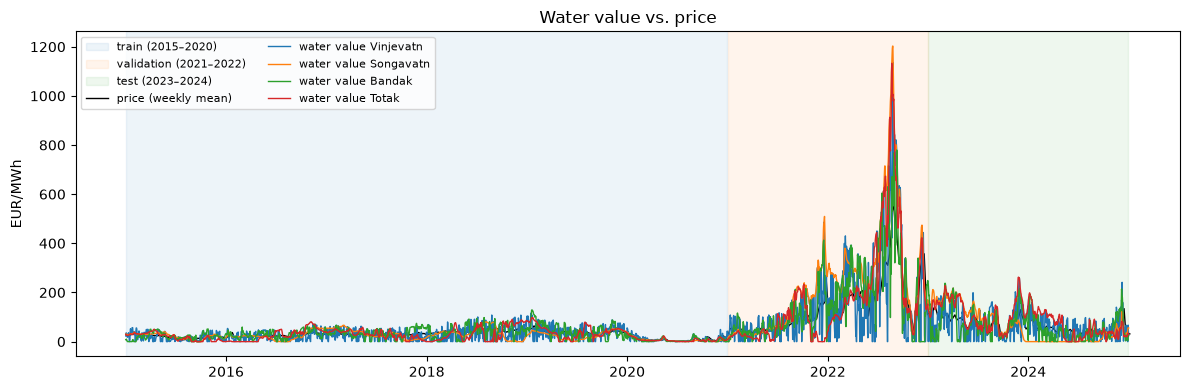

In [13]:
reservoirs = ["Vinjevatn", "Songavatn", "Bandak", "Totak"]   # Tokke, Songa, Hogga, Vinje (via Totak)
price_weekly = day_ahead_price["price"].loc[:"2024"].resample("W").mean()

fig, ax = plt.subplots(figsize=(12, 4))
shade_periods(ax)
ax.plot(price_weekly.index, price_weekly, color="black", linewidth=1, label="price (weekly mean)")
for r in reservoirs:
    ax.plot(water_value.index, water_value[r], linewidth=1, label=f"water value {r}")
ax.set_ylabel("EUR/MWh")
ax.set_title("Water value vs. price")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()

price_daily = price_2024.resample("D").mean()

for r in reservoirs:
    corr = water_value[r].loc[:"2024"].corr(price_daily)
    print(f"{r}: correlation with daily price = {corr:.2f}")

groups = water_value.T.groupby(list(water_value.T.columns)).groups
for members in groups.values():
    print(list(members))

r = "Songavatn"
near_zero = water_value[r] <= 0.5
print(f"Share of days with water value ≈ 0: {near_zero.mean():.1%}")
print(f"Average fill on those days: {fill.loc[near_zero, r].mean():.2f}")
print(f"Average fill other days:    {fill.loc[~near_zero, r].mean():.2f}")

The water values follow the price closely (daily correlation 0.79–0.93). Only 9 distinct series exist for 17 reservoirs, because connected reservoirs share a water value (e.g. Totak, Venemo, Vaamarvatn and Hyljelihyl). On ~9% of days the water value is close to 0, this happens mainly when the reservoir is nearly full (Songavatn: average fill 0.90 on those days vs 0.64 otherwise), since stored water would otherwise be spilled. The unit-commitment decision is essentially "produce when price > water value", so price minus water value is expected to be a key feature.

Bandak         1.18
Vinjevatn      1.12
Langeidvatn    1.06
Byrtevatn      1.05
Staavatn       1.05
dtype: float64
count    3654.00
mean        0.76
std         0.05
min         0.60
25%         0.73
50%         0.76
75%         0.78
max         1.18
Name: Bandak, dtype: float64


date
2023-09-03    0.74
2023-09-17    0.76
2023-10-01    0.84
2023-10-15    0.89
2023-10-29    0.91
2023-11-12    0.92
2023-11-26    0.93
2023-12-10    0.93
2023-12-24    0.94
2024-01-07    0.95
2024-01-21    0.95
2024-02-04    0.96
2024-02-18    0.97
2024-03-03    0.96
2024-03-17    0.89
2024-03-31    0.82
2024-04-14    0.75
2024-04-28    0.69
2024-05-12    0.65
Freq: 2W-SUN, Name: Songavatn, dtype: float64

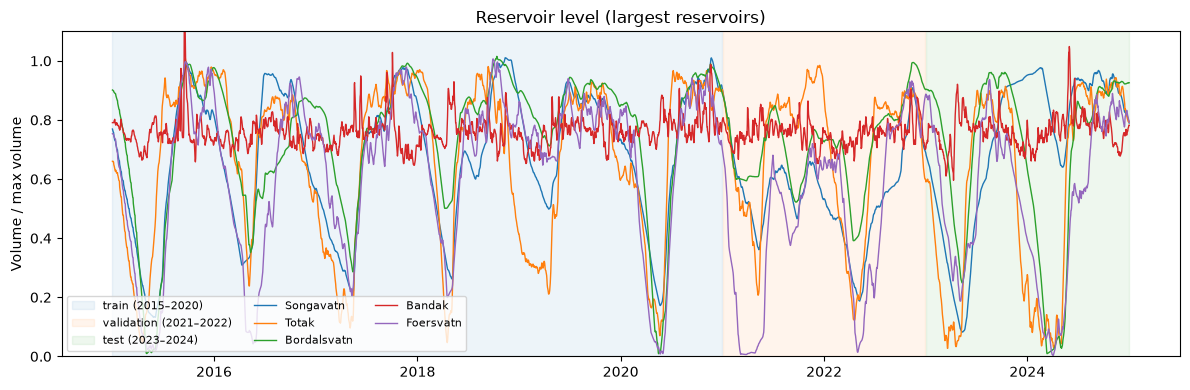

In [14]:
big = ["Songavatn", "Totak", "Bordalsvatn", "Bandak", "Foersvatn"]
fig, ax = plt.subplots(figsize=(12, 4))
shade_periods(ax)
for r in big:
    ax.plot(fill.index, fill[r], linewidth=1, label=r)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Volume / max volume")
ax.set_title("Reservoir level (largest reservoirs)")
ax.legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout()

print(fill.max().sort_values(ascending=False).round(2).head(5))   # highest fill per reservoir
print(fill["Bandak"].describe().round(2))                            # mean ≈ 0.76, std ≈ 0.05

fill["Songavatn"].loc["2023-09":"2024-04"].resample("2W").mean().round(2)

The large reservoirs follow a yearly cycle: drawn down through winter, lowest in April–May, refilled by snowmelt in June. Bandak is an exception, kept in a narrow band around 0.75. Some reservoirs briefly exceed `max_vol` (Bandak up to 1.18), likely during floods, so fill levels may be clipped at 1. Notable years: Totak stayed low through 2019, Foersvatn was almost empty in spring 2021, and Songavatn kept filling through winter 2023–24 instead of being drawn down, which may indicate low production at Songa. The fill level relative to `max_vol` is likely most informative near the extremes (nearly empty or nearly full).

Autumn mean 1958–2014: 104 m³/s
Autumn mean 2015–2024: 135 m³/s


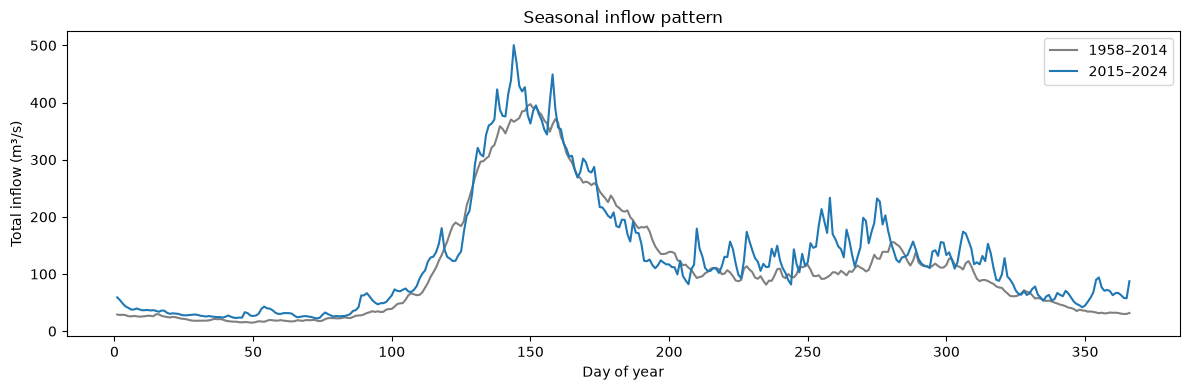

In [15]:
total_inflow = inflow.sum(axis=1).resample("D").mean()

def seasonal_profile(series):
    return series.groupby(series.index.dayofyear).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(seasonal_profile(total_inflow.loc[:"2014"]), label="1958–2014", color="grey")
ax.plot(seasonal_profile(total_inflow.loc["2015":"2024"]), label="2015–2024", color="tab:blue")
ax.set_xlabel("Day of year")
ax.set_ylabel("Total inflow (m³/s)")
ax.set_title("Seasonal inflow pattern")
ax.legend()
plt.tight_layout()

autumn = lambda s: s[(s.index.month >= 9) & (s.index.month <= 11)].mean()
print(f"Autumn mean 1958–2014: {autumn(total_inflow.loc[:'2014']):.0f} m³/s")
print(f"Autumn mean 2015–2024: {autumn(total_inflow.loc['2015':'2024']):.0f} m³/s")

Inflow is dominated by snowmelt, peaking around day 140–160 (late May–early June). Compared with 1958–2014, the recent period (2015–2024) has a higher spring peak and noticeably more inflow in autumn (September–November mean 135 m³/s vs 104 m³/s, about 30% higher) and winter, consistent with milder and wetter conditions. The long history provides a reference for "normal" inflow at each time of year, which can be used to build an inflow-anomaly feature (this week's inflow / normal).

## 4. Inputs vs. decisions

In [16]:
# Find which reservoir(s) each plant draws water from, using the topology file
plant_sources = {}
for conn in topology["connections"]:
    if conn["to_type"] == "plant" and conn["from_type"] in ("reservoir", "tunnel"):
        plant_sources.setdefault(conn["to"], []).append(conn["from"])

# Some plants get water through a tunnel: replace the tunnel with the reservoir it starts at
tunnel_sources = {conn["to"]: conn["from"] for conn in topology["connections"]
                  if conn["to_type"] == "tunnel" and conn["from_type"] == "reservoir"}
plant_reservoir = {plant: [tunnel_sources.get(s, s) for s in sources]
                   for plant, sources in plant_sources.items()}

for plant, reservoirs in plant_reservoir.items():
    print(f"{plant:12s} <- {reservoirs}")

Hogga        <- ['Bandak']
Tokke        <- ['Vinjevatn']
Lio          <- ['Byrtevatn']
Byrte        <- ['Botnedalsvatn']
Vinje        <- ['Vaamarvatn']
Haukeli      <- ['Vatjern']
Songa        <- ['Songavatn', 'Bitdalsvatn']
Kjela        <- ['Foersvatn']
Vesle Kjela  <- ['Kjelavatn']


In [17]:
# Hourly price for every case: one row per case, one column per hour (t0..t167)
starts = unit_commitment_decisions.index
price = day_ahead_price["price"]
P = np.array([price.loc[s : s + pd.Timedelta(hours=167)].to_numpy() for s in starts])
P.shape   # (2922, 168), same layout as Y[:, unit, :]

(2922, 168)

In [18]:
def unit_water_value(unit, at_end=False):
    """Water value for the unit's reservoir(s), at the start or the end of each case."""
    plant = unit.rsplit("_G", 1)[0]
    dates = starts + pd.Timedelta(days=7) if at_end else starts
    return water_value.loc[dates, plant_reservoir[plant]].mean(axis=1).to_numpy()

bins = [-np.inf, -20, -10, -5, -2, 0, 2, 5, 10, 20, np.inf]   # EUR/MWh

def on_rate_by_diff(unit, at_end=False):
    k = units.index(unit)
    diff = P - unit_water_value(unit, at_end)[:, None]
    df = pd.DataFrame({"diff": diff.ravel(), "on": Y[:, k, :].ravel()})
    df["bin"] = pd.cut(df["diff"], bins)
    return df.groupby("bin", observed=False)["on"].mean()

on_rate_by_diff("Tokke_G1")

bin
(-inf, -20.0]     0.497167
(-20.0, -10.0]    0.614171
(-10.0, -5.0]     0.648808
(-5.0, -2.0]      0.668515
(-2.0, 0.0]       0.756934
(0.0, 2.0]        0.764209
(2.0, 5.0]        0.755831
(5.0, 10.0]       0.751357
(10.0, 20.0]      0.769386
(20.0, inf]       0.717846
Name: on, dtype: float64

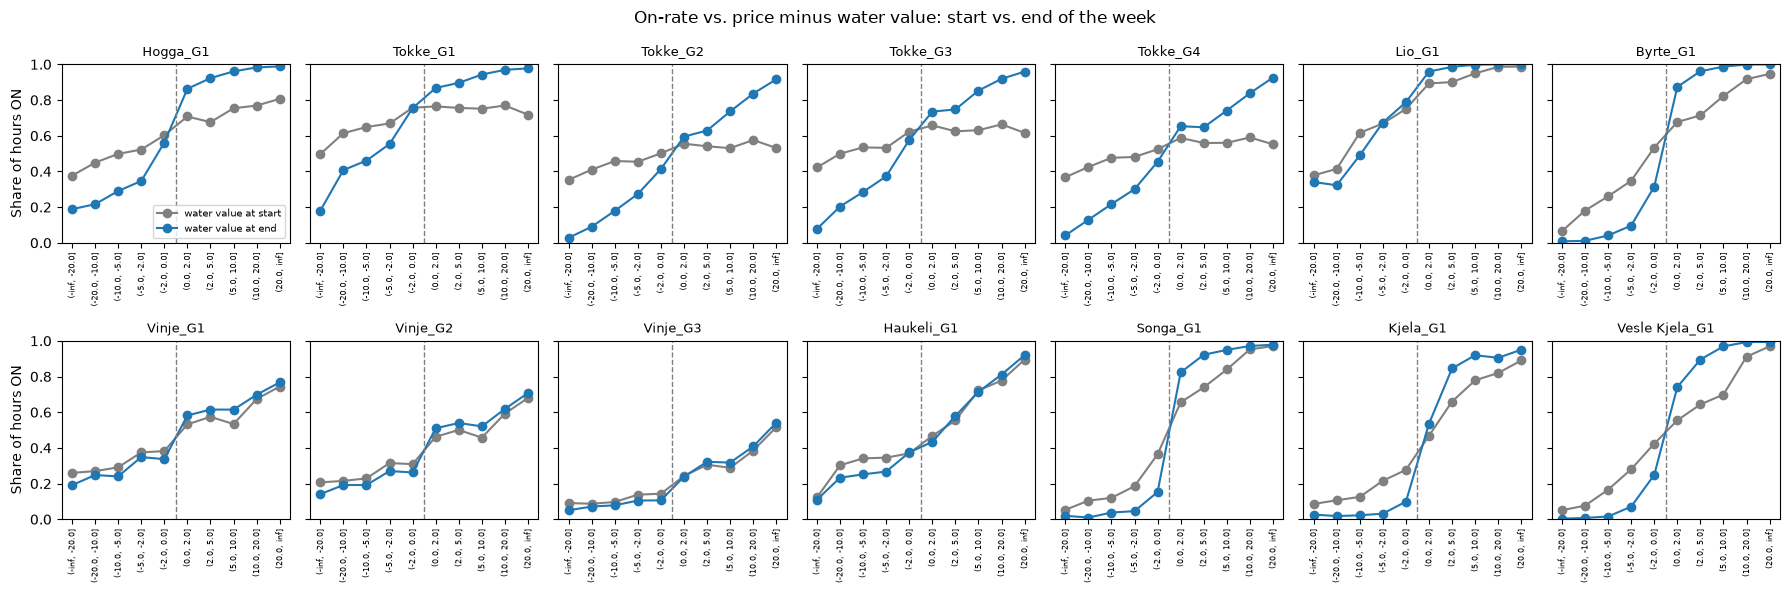

In [19]:
fig, axes = plt.subplots(2, 7, figsize=(18, 6), sharey=True)
x = np.arange(len(bins) - 1)
labels = [str(b) for b in on_rate_by_diff(units[0]).index]

for ax, unit in zip(axes.ravel(), units):
    ax.plot(x, on_rate_by_diff(unit).to_numpy(), marker="o", color="grey", label="water value at start")
    ax.plot(x, on_rate_by_diff(unit, at_end=True).to_numpy(), marker="o", color="tab:blue", label="water value at end")
    ax.axvline(4.5, color="grey", linestyle="--", linewidth=1)
    ax.set_title(unit, fontsize=9)
    ax.set_xticks(x, labels, rotation=90, fontsize=6)
    ax.set_ylim(0, 1)

axes[0, 0].set_ylabel("Share of hours ON")
axes[1, 0].set_ylabel("Share of hours ON")
axes[0, 0].legend(fontsize=7)
fig.suptitle("On-rate vs. price minus water value: start vs. end of the week")
plt.tight_layout()

In [20]:
# On-rate in the lowest bin (price far below the water value) and the highest bin (far above),
# using the start vs. end water value
comparison = pd.DataFrame({
    unit: {
        "start: far below": on_rate_by_diff(unit).iloc[0],
        "start: far above": on_rate_by_diff(unit).iloc[-1],
        "end: far below": on_rate_by_diff(unit, at_end=True).iloc[0],
        "end: far above": on_rate_by_diff(unit, at_end=True).iloc[-1],
    }
    for unit in units
}).T.round(2)

comparison

,start: far below,start: far above,end: far below,end: far above
Hogga_G1,0.38,0.81,0.19,0.99
Tokke_G1,0.50,0.72,0.18,0.98
Tokke_G2,0.35,0.53,0.03,0.92
Tokke_G3,0.42,0.62,0.08,0.96
Tokke_G4,0.37,0.55,0.04,0.93
Lio_G1,0.38,0.99,0.34,1.00
Byrte_G1,0.07,0.95,0.01,1.00
Vinje_G1,0.26,0.74,0.19,0.77
Vinje_G2,0.21,0.68,0.14,0.71
Vinje_G3,0.09,0.52,0.05,0.54


The plot compares the on-rate against price minus water value, using the water value at the **start** of the week (grey) and at the **end** of the week (blue). For all 14 units, the end water value separates on and off at least as well. The on-rate is lower when the price is far below it and higher or equal when the price is far above it. How much it helps differs between units:

* **Large improvement** for Hogga, all Tokke units and Kjela. For example, Tokke_G2 goes from 0.35 → 0.53 with the start value to 0.03 → 0.92 with the end value, and Hogga_G1 from 0.38 → 0.81 to 0.19 → 0.99. The Tokke units barely follow the price rule when the start water value is used, but follow it clearly once the end water value is used.
* **Small improvement** for Byrte, Songa and Vesle Kjela, which already had a sharp jump with the start value.
* **Almost no change** for Lio, Haukeli and Vinje. Vinje_G1 only reaches 0.77 and Vinje_G3 0.54 even when the price is far above the water value, so the threshold alone does not explain these units. Likely reasons are the order in which units within a plant are started, and the cascade: Vinje releases its water into Vinjevatn, which affects the units downstream.

This makes sense given how the data was generated. The end water value is the value the optimizer assigns to water left in the reservoir after the week, so it is the price it compares against when deciding whether to produce. Based on this, **price minus end water value** was chosen as the core feature in the model, while the start water value is kept as an additional feature (the difference between start and end indicates whether the water value is expected to rise or fall). For Vinje, Lio and Haukeli, additional features describing unit order and upstream/downstream conditions are needed.

Two further observations:
* The relationship is not an on/off switch: even far above the threshold, some units are on far less than 100% of the time. Start costs, reservoir level and inflow likely also matter, which motivates features for neighbouring hours, fill level and inflow.
* Plants with several units seem to start them in a fixed order (Vinje G1 > G2 > G3 and Tokke G1 > G3 > G4 > G2 in on-rate), so `unit` itself must be a feature. The same price difference affects different units differently.

## 5. How consistent are the labels?

The cases are daily rolling: each case starts one day after the previous one, so two consecutive cases share 6 days (144 hours) with the same prices and inflow. Comparing SHOP's decisions for the same calendar hour in two consecutive cases shows how stable the labels are.

In [ ]:
spacing = unit_commitment_decisions.index.to_series().diff().dropna().value_counts()
print("Time between consecutive cases:", spacing.to_dict())

# Case i, hours 24–167 and case i+1, hours 0–143 cover the same calendar hours
same_a, same_b = Y[:-1, :, 24:], Y[1:, :, :144]
print(f"Same decision overall: {(same_a == same_b).mean():.3f}")

# For plants with several identical units: does the NUMBER of running units agree?
for plant in ["Tokke", "Vinje"]:
    idx = [k for k, u in enumerate(units) if u.rsplit("_G", 1)[0] == plant]
    count_same = (same_a[:, idx].sum(axis=1) == same_b[:, idx].sum(axis=1)).mean()
    print(f"{plant}: same number of units on in {count_same:.3f} of the hours")

agreement = pd.DataFrame({
    "same decision": (same_a == same_b).mean(axis=(0, 2)),
    "on-rate": Y.mean(axis=(0, 2)),
}, index=units).sort_values("same decision")
agreement.round(3)